# Ejercicio 04 · Clasificador visual con CNN y Model Card

**Asignatura:** INF-8239 Ciencia de Datos II (UASD) · **Código:** U02.E04 · **Evidencia de:** U02.LAB07

Este cuaderno integra, en una sola ejecución reproducible, la auditoría de datos, el entrenamiento del baseline denso y de la CNN pequeña sobre la **misma partición**, las curvas, las métricas por clase, los errores, el costo y las pruebas.

Se ejecuta desde la raíz del repositorio, sin tocar los resultados oficiales de `reports/` ni de `models/`:

```powershell
uv run --with nbconvert --with ipykernel python -m nbconvert --to notebook --execute --inplace --ExecutePreprocessor.timeout=3600 notebooks/ejercicio04.ipynb
```

Las cifras de este cuaderno se comparan con las de la corrida oficial (`reports/cv_metrics.json`). Con semilla 42 y operaciones deterministas se espera una diferencia de 0 en el F1 macro.

In [1]:
import json
import os
import platform
import random
import sys
from pathlib import Path
from time import perf_counter

os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "3")  # menos ruido de TensorFlow en el cuaderno

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT / "src"))

import keras
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score

from inf8239_u02_cv.data import normalize_images
from inf8239_u02_cv.models import build_cnn, build_dense

print("Python:", platform.python_version(), "|", platform.platform())
print("TensorFlow:", tf.__version__, "| Keras:", keras.__version__, "| NumPy:", np.__version__)
print("GPU detectada:", tf.config.list_physical_devices("GPU"))
print("Raiz del proyecto:", ROOT)

Python: 3.12.14 | Windows-11-10.0.26300-SP0
TensorFlow: 2.21.0 | Keras: 3.15.1 | NumPy: 2.5.3


GPU detectada: []
Raiz del proyecto: C:\INF8239_U02_CV_Proyecto_Base


## 1. Auditoría y partición reproducible

La partición es determinista: **entrenamiento** = primeras 54 000 imágenes del conjunto de entrenamiento original, **validación** = las últimas 6 000 (sin estratificar) y **prueba** = las 10 000 oficiales. Para comprobar que es reproducible, se recalcula la huella SHA-256 de cada partición y se compara con la que guardó `scripts/audit_cv.py` en `reports/audit_cv.json`.

train imagenes= 54000 forma=[28, 28] dtype=uint8 pixeles=[0, 255] duplicados=0 huella=ab0e9065dde7cc48 coincide_con_auditoria=True
valid imagenes=  6000 forma=[28, 28] dtype=uint8 pixeles=[0, 255] duplicados=0 huella=c2d8795551cb3fde coincide_con_auditoria=True
test  imagenes= 10000 forma=[28, 28] dtype=uint8 pixeles=[0, 255] duplicados=0 huella=9f1ec356a747bfe4 coincide_con_auditoria=True
Solapamiento entre particiones (imagenes identicas): {'valid_and_train': 0, 'test_and_train': 0, 'test_and_valid': 0}


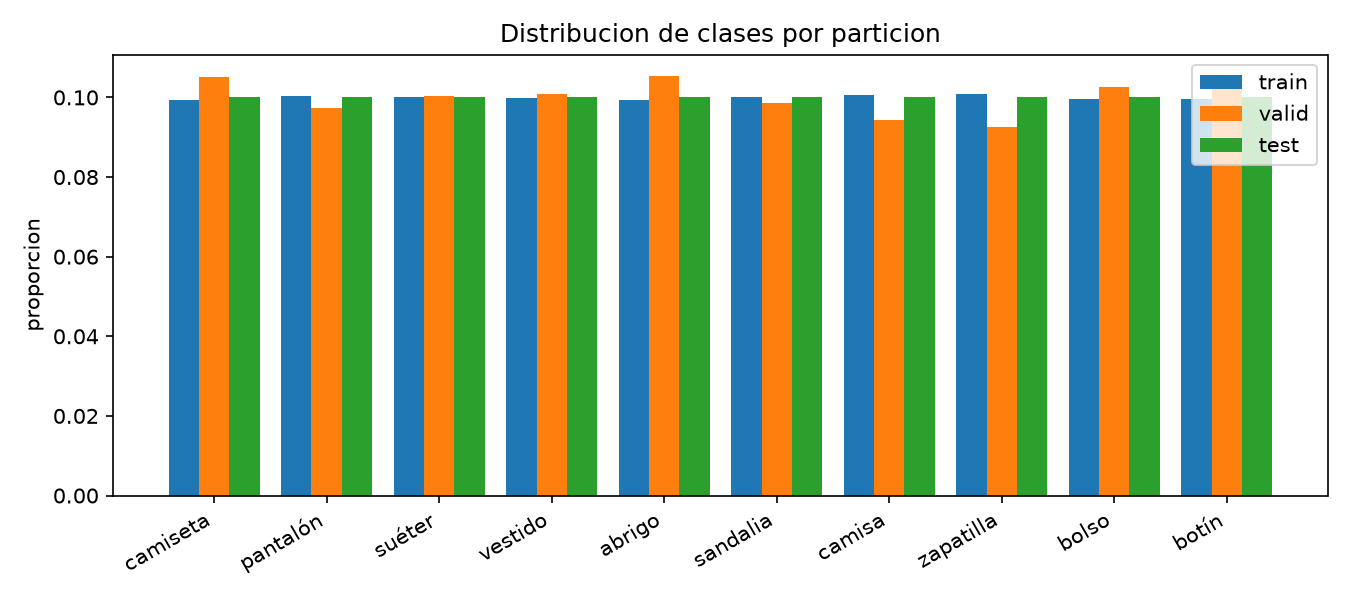

In [2]:
import hashlib
from IPython.display import Image, display

audit = json.loads((ROOT / "reports" / "audit_cv.json").read_text(encoding="utf-8"))
(x_all_raw, y_all), (x_test_raw, y_test) = tf.keras.datasets.fashion_mnist.load_data()
parts = {
    "train": (x_all_raw[:-6000], y_all[:-6000]),
    "valid": (x_all_raw[-6000:], y_all[-6000:]),
    "test": (x_test_raw, y_test),
}


def fingerprint(x, y):
    digest = hashlib.sha256()
    digest.update(np.ascontiguousarray(x).tobytes())
    digest.update(np.ascontiguousarray(y).tobytes())
    return digest.hexdigest()[:16]


for name, (x, y) in parts.items():
    info = audit["partitions"][name]
    huella = fingerprint(x, y)
    print(f"{name:5s} imagenes={len(x):>6} forma={list(x.shape[1:])} dtype={x.dtype} "
          f"pixeles=[{x.min()}, {x.max()}] duplicados={info['duplicate_images_within']} "
          f"huella={huella} coincide_con_auditoria={huella == info['fingerprint']}")
print("Solapamiento entre particiones (imagenes identicas):", audit["overlap_identical_images"])
display(Image(filename=str(ROOT / "reports" / "audit_class_distribution.png")))

In [3]:
names_es = ["camiseta", "pantalón", "suéter", "vestido", "abrigo",
            "sandalia", "camisa", "zapatilla", "bolso", "botín"]

x_all = normalize_images(x_all_raw)
x_test = normalize_images(x_test_raw)
x_train, y_train = x_all[:-6000], y_all[:-6000]
x_valid, y_valid = x_all[-6000:], y_all[-6000:]
print("Formas:", x_train.shape, x_valid.shape, x_test.shape)
print("Tipo:", x_train.dtype, "| rango tras normalizar:", float(x_train.min()), "a", float(x_train.max()))
print("Imagenes de prueba por clase:", dict(zip(names_es, np.bincount(y_test).tolist())))

Formas: (54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)
Tipo: float32 | rango tras normalizar: 0.0 a 1.0
Imagenes de prueba por clase: {'camiseta': 1000, 'pantalón': 1000, 'suéter': 1000, 'vestido': 1000, 'abrigo': 1000, 'sandalia': 1000, 'camisa': 1000, 'zapatilla': 1000, 'bolso': 1000, 'botín': 1000}


## 2. Entrenamiento: baseline denso y CNN (misma partición, semilla 42, 8 épocas)

Ambos modelos usan Adam, entropía cruzada categórica dispersa, lote de 128 y `EarlyStopping` (paciencia 2, restaura los mejores pesos). Se fija la semilla justo antes de entrenar, en el mismo orden que `scripts/train_cv.py` (primero el denso y luego la CNN).

In [4]:
SEED = 42
os.environ.setdefault("TF_DETERMINISTIC_OPS", "1")
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

trained, histories, preds, times = {}, {}, {}, {}
for name, factory in {"dense": build_dense, "cnn": build_cnn}.items():
    print(f"=== Entrenando {name} ===")
    model = factory(tf)
    model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    callbacks = [tf.keras.callbacks.EarlyStopping(patience=2, restore_best_weights=True)]
    inicio = perf_counter()
    history = model.fit(x_train, y_train, validation_data=(x_valid, y_valid),
                        epochs=8, batch_size=128, callbacks=callbacks, verbose=2)
    times[name] = perf_counter() - inicio
    trained[name] = model
    histories[name] = history.history
    preds[name] = model.predict(x_test, verbose=0).argmax(axis=1)
print("Segundos de entrenamiento:", {k: round(v, 1) for k, v in times.items()})

=== Entrenando dense ===


Epoch 1/8


422/422 - 6s - 13ms/step - accuracy: 0.7977 - loss: 0.6009 - val_accuracy: 0.8407 - val_loss: 0.4510


Epoch 2/8


422/422 - 2s - 6ms/step - accuracy: 0.8508 - loss: 0.4320 - val_accuracy: 0.8535 - val_loss: 0.4120


...

Epoch 7/8


422/422 - 27s - 64ms/step - accuracy: 0.7458 - loss: 0.7197 - val_accuracy: 0.7940 - val_loss: 0.6113


Epoch 8/8


422/422 - 27s - 64ms/step - accuracy: 0.7544 - loss: 0.6955 - val_accuracy: 0.7992 - val_loss: 0.5870


Segundos de entrenamiento: {'dense': 23.0, 'cnn': 228.5}


In [5]:
for name, model in trained.items():
    print(f"--- {model.name} ({name}) ---")
    model.summary()

--- dense_baseline (dense) ---


Model: "dense_baseline"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten (Flatten)                    │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 152,672 (596.38 KB)

 Trainable params: 50,890 (198.79 KB)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 28, 28, 32)          │             320 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 14, 14, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 14, 14, 64)          │          18,496 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 7, 7, 64)            │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 64)                  │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 64)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 58,400 (228.13 KB)

 Trainable params: 19,466 (76.04 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 38,934 (152.09 KB)

## 3. Curvas de entrenamiento y validación

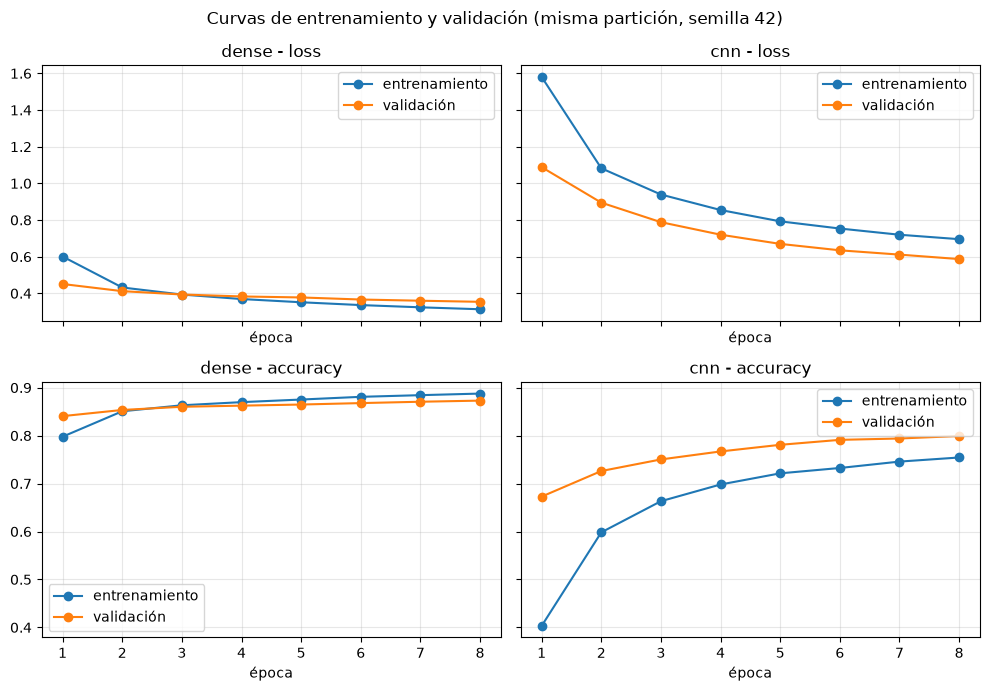

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(10, 7), sharex=True, sharey="row")
for col, name in enumerate(["dense", "cnn"]):
    h = histories[name]
    epocas = range(1, len(h["loss"]) + 1)
    for row, metric in enumerate(["loss", "accuracy"]):
        ax = axes[row][col]
        ax.plot(epocas, h[metric], marker="o", label="entrenamiento")
        ax.plot(epocas, h["val_" + metric], marker="o", label="validación")
        ax.set_title(f"{name} - {metric}")
        ax.set_xlabel("época")
        ax.grid(alpha=0.3)
        ax.legend()
fig.suptitle("Curvas de entrenamiento y validación (misma partición, semilla 42)")
fig.tight_layout()
plt.show()

**Lectura.** En el denso ambas pérdidas bajan y quedan muy cerca (sin sobreajuste: la pérdida de validación no sube). En la CNN ambas pérdidas bajan pero siguen altas y todavía en descenso en la época 8; la validación queda por encima del entrenamiento en exactitud porque la métrica de entrenamiento se calcula con el `Dropout` activo y se promedia durante la época. La CNN **no había convergido** en 8 épocas (hipótesis a contrastar con más épocas).

## 4. Métricas globales y por clase (conjunto de prueba)

In [7]:
official = json.loads((ROOT / "reports" / "cv_metrics.json").read_text(encoding="utf-8"))
for name in ["dense", "cnn"]:
    f1 = f1_score(y_test, preds[name], average="macro")
    print(f"=== {name} | F1 macro = {f1:.4f} | oficial = {official[name]['f1_macro']:.4f} "
          f"| diferencia = {abs(f1 - official[name]['f1_macro']):.2e}")
    print(classification_report(y_test, preds[name], target_names=names_es, digits=3))

=== dense | F1 macro = 0.8647 | oficial = 0.8647 | diferencia = 0.00e+00
              precision    recall  f1-score   support

    camiseta      0.791     0.848     0.819      1000
    pantalón      0.982     0.969     0.975      1000
      suéter      0.836     0.684     0.752      1000
     vestido      0.837     0.903     0.869      1000
      abrigo      0.711     0.870     0.782      1000
    sandalia      0.935     0.962     0.948      1000
      camisa      0.719     0.597     0.652      1000
   zapatilla      0.929     0.940     0.934      1000
       bolso      0.972     0.953     0.963      1000
       botín      0.967     0.937     0.952      1000

    accuracy                          0.866     10000
   macro avg      0.868     0.866     0.865     10000
weighted avg      0.868     0.866     0.865     10000

=== cnn | F1 macro = 0.7892 | oficial = 0.7892 | diferencia = 0.00e+00
              precision    recall  f1-score   support

    camiseta      0.643     0.806     0.71

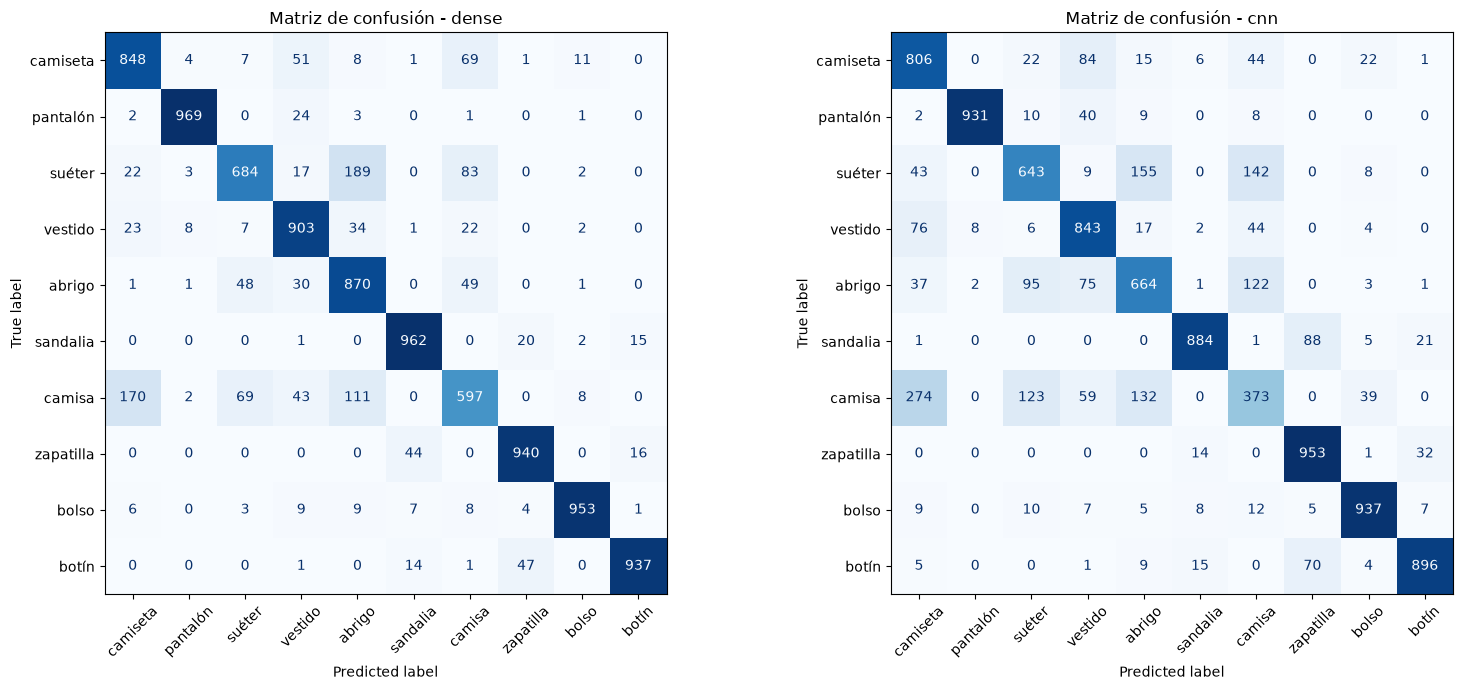

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, name in zip(axes, ["dense", "cnn"]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[name], display_labels=names_es, cmap="Blues",
        xticks_rotation=45, ax=ax, colorbar=False)
    ax.set_title(f"Matriz de confusión - {name}")
fig.tight_layout()
plt.show()

## 5. Errores de la CNN

Primeros 16 errores del conjunto de prueba (R = clase real, P = predicha). No son una muestra aleatoria: ilustran patrones; la frecuencia real está en la matriz de confusión.

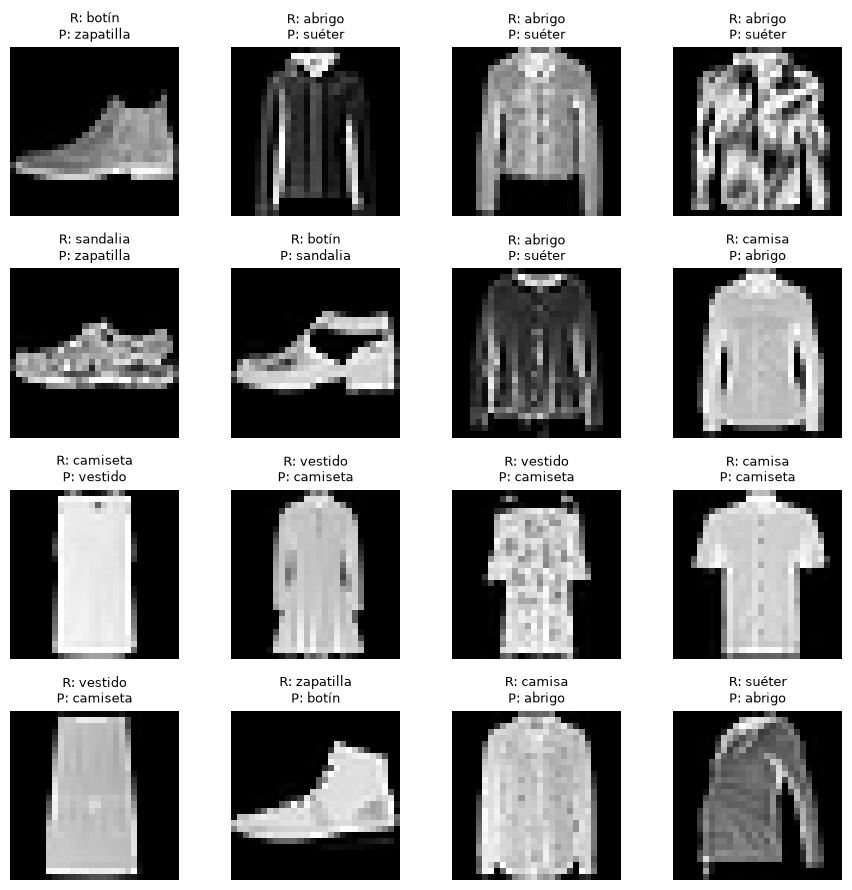

In [9]:
wrong = np.where(preds["cnn"] != y_test)[0][:16]
fig, axes = plt.subplots(4, 4, figsize=(9, 9))
for ax, i in zip(axes.ravel(), wrong):
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    ax.set_title(f"R: {names_es[y_test[i]]}\nP: {names_es[preds['cnn'][i]]}", fontsize=9)
    ax.axis("off")
fig.tight_layout()
plt.show()

## 6. Costo y tamaño

Los tiempos absolutos dependen de la carga de la CPU (equipo portátil con gestión de energía) y varían entre ejecuciones: compárense los tiempos de este cuaderno con los de la corrida oficial impresos abajo. Lo que se mantiene estable es la razón de inferencia entre los dos modelos (≈ 2,8×); la razón de entrenamiento varía entre ejecuciones (aprox. 10× a 14×).

In [10]:
print("Parámetros:", {n: trained[n].count_params() for n in trained})
print("Entrenamiento en este cuaderno (s):", {n: round(times[n], 1) for n in times})
print("Entrenamiento en la corrida oficial (s):",
      {n: round(official[n]["train_seconds"], 1) for n in official})

Parámetros: {'dense': 50890, 'cnn': 19466}
Entrenamiento en este cuaderno (s): {'dense': 23.0, 'cnn': 228.5}
Entrenamiento en la corrida oficial (s): {'dense': 13.0, 'cnn': 187.6}


In [11]:
import subprocess

env = dict(os.environ, PYTHONPATH=str(ROOT / "src"))
resultado = subprocess.run([sys.executable, "scripts/bench_inference.py"],
                           capture_output=True, text=True, env=env, cwd=str(ROOT))
print(resultado.stdout)
if resultado.returncode != 0:
    print("El script terminó con error:")
    print(resultado.stderr[-1500:])

denso: mediana 0.0931 ms/imagen (min 0.0897, max 0.1158)
cnn: mediana 0.2633 ms/imagen (min 0.2439, max 0.2835)
denso archivo sin optimizador: 220815 bytes
cnn archivo sin optimizador: 105347 bytes



## 7. Pruebas

In [12]:
import pytest

codigo = pytest.main(["-q", "tests", "-p", "no:cacheprovider"])
print("Código de salida de pytest:", int(codigo))

.

.

.

                                                                                                                                      [100%]


3 passed in 0.18s


Código de salida de pytest: 0


## 8. Decisión técnica

Con esta configuración (misma partición, semilla 42, 8 épocas, CPU), **se elige el baseline denso**: obtiene mayor F1 macro (0,865 frente a 0,789), es mejor en F1 en las 10 clases, entrena entre unas 10 y 14 veces más rápido según la ejecución (13,0 s frente a 187,6 s en la corrida oficial) y predice unas 2,8 veces más rápido. La CNN solo gana en el tamaño del archivo del modelo (unos 103 KB frente a 216 KB, sin optimizador) y en el número de parámetros.

La CNN no se descarta: sus pérdidas seguían bajando en la época 8, y su diseño (`GlobalAveragePooling2D` más `Dropout`) puede limitar su capacidad. Antes de usarla en otro dominio habría que entrenarla hasta que converja, volver a compararla por clase y validar con datos reales del dominio. Fashion-MNIST es un benchmark didáctico y estas conclusiones no se transfieren a otros dominios.